```mermaid
flowchart TB
    A["<b>1. Raw file</b><br/>FID + acquisition settings"] --> B["<b>2. Spectrum</b><br/>Fourier transform, phase correction"]
    B --> C["<b>3. Areas</b><br/>one fixed ppm window per compound,<br/>area above the baseline"]
    C --> D["<b>4. Shares</b><br/>each area / sum of the areas<br/>e.g. ³¹P: H₃PO₄ 66 %, MMSPA 31 %, BMSPA 4 %"]
    D --> E["<b>5. Comparison</b><br/>the kinetic model predicts the same shares"]
```

Example: `2 % H2O`, last room-temperature ³¹P (after the 80 °C step): an FID, 256 scans, d1 5 s, 45° pulse, NOE off. The cell runs the functions of the pipeline one at a time on the raw file and draws:

1. the first points of the FID: the digital filter delays the echo top by ~20 points; the code rolls it to point 0;
2. the region that is integrated, before and after phasing;
3. the integration windows and the two polynomial baselines, zoomed on the foot of the lines.

In [1]:
import json
import sys
from pathlib import Path

# Run from notebooks/ or from the repository root
REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from demo import style
from kinetics.data.lab_nmr import (LINE_BROADENING_HZ, _polynomial_baseline, build_lab_nmr_inventory, calculate_area_shares,
                                   calculate_spectrum, phase_spectrum, read_jdf, refine_window_phase)
from kinetics.data.observables import P_WINDOWS_PPM, RT_MAX_C, load_lab_observables, load_lab_sample_folders
from kinetics.paths import lab_nmr_dir

style.apply_style()
FILE = lab_nmr_dir() / '5% TMSPa + 2v% H2O in EC-DEC/After Ramping Temperature/WW-NG 5%TMSPa+2v%H2O EC-DEC 22oC after 8oC_31P-1-1.jdf'
REGION = (-32.0, 6.0)          # ppm: the ³¹P region whose phase is refined and whose areas are summed

In [2]:
print("File header")
jdf = read_jdf(FILE)
p = jdf['params']
pd.Series({'nucleus (header)': jdf['nucleus'], 'data': 'FID' if jdf['unit'] == 's' else 'processed spectrum', 'points': len(jdf['data']),
           'scans': p['scans'], 'relaxation delay (s)': p['relaxation_delay'], 'pulse angle (°)': p['x_angle'], 'NOE': p['irr_noe'],
           'temperature (°C)': round(p['temp_get'], 1), 'lock': p['solvent'], 'experiment file': p['experiment'],
           'frequency (MHz)': round(p['x_freq'] / 1e6, 3), 'sweep (Hz)': round(p['x_sweep'], 1)}, name='header').to_frame()

File header


,header
nucleus (header),31P
data,FID
points,32768
scans,256
relaxation delay (s),5.0
pulse angle (°),45.0
NOE,FALSE
temperature (°C),22.9
lock,DMSO-D6
experiment file,carbon.jxp


### Processing

In [3]:
# FID (time) -> spectrum (ppm)
ppm, unphased = calculate_spectrum(jdf['data'], sweep_Hz=p['x_sweep'], freq_MHz=p['x_freq'] / 1e6, offset_ppm=p['x_offset'],
                                   line_broadening_Hz=LINE_BROADENING_HZ['31P'])

# Phase correction
_, (p0, p1) = phase_spectrum(unphased)
phased = unphased * np.exp(1j * (p0 + p1 * np.linspace(-0.5, 0.5, len(unphased))))

# Refine phase in the region of interest and calculate area shares
final = refine_window_phase(ppm, phased, REGION).real

# Calculate area shares of the ³¹P spectrum in the defined windows
shares = calculate_area_shares(ppm, final, P_WINDOWS_PPM, region_ppm=REGION)

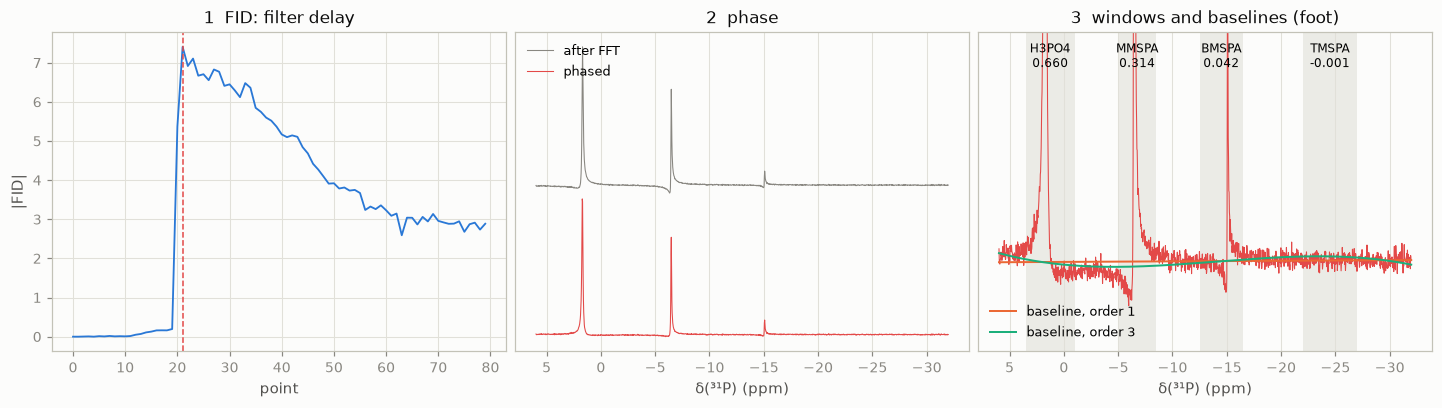

,share,sigma_noise,sigma_baseline,sigma,share_local,share_poly1,share_poly3
TMSPA,-0.001,0.003,0.012,0.012,-0.001,0.004,-0.020
BMSPA,0.042,0.003,0.007,0.008,0.028,0.042,0.042
MMSPA,0.314,0.002,0.012,0.012,0.318,0.294,0.314
H3PO4,0.660,0.003,0.004,0.005,0.655,0.660,0.664


In [4]:
# Plotting
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout='constrained')
ax = axes[0]
delay = int(np.argmax(np.abs(jdf['data'][:256])))
ax.plot(np.abs(jdf['data'][:80]), color=style.SERIES[0], linewidth=1.2)
ax.axvline(delay, color=style.SERIES[7], linestyle='--', linewidth=1)
ax.set(title='1  FID: filter delay', xlabel='point', ylabel='|FID|')
inside = (ppm >= REGION[0]) & (ppm <= REGION[1])
x = ppm[inside]
ax = axes[1]
ax.plot(x, unphased.real[inside] / final[inside].max() + 1.1, color=style.INK_MUTED, linewidth=0.7, label='after FFT')
ax.plot(x, final[inside] / final[inside].max(), color=style.SERIES[7], linewidth=0.7, label='phased')
ax.set(title='2  phase', xlabel='δ(³¹P) (ppm)', yticks=[])
ax.legend(loc='upper left')
ax = axes[2]
y = final[inside]
signal_free = np.ones(len(x), dtype=bool)
for lo, hi in P_WINDOWS_PPM.values():
    signal_free &= ~((x >= lo - 0.3) & (x <= hi + 0.3))
ax.plot(x, y, color=style.SERIES[7], linewidth=0.7)
for order, color in ((1, style.SERIES[1]), (3, style.SERIES[2])):
    ax.plot(x, _polynomial_baseline(x, y, signal_free, order), color=color, linewidth=1.3, label=f'baseline, order {order}')
for name, (lo, hi) in P_WINDOWS_PPM.items():
    ax.axvspan(lo, hi, color=style.GRID, alpha=0.6, linewidth=0)
    ax.text(0.5 * (lo + hi), 0.97, f"{name}\n{shares.loc[name, 'share']:.3f}", ha='center', va='top', fontsize=8,
            transform=ax.get_xaxis_transform())
ax.set_ylim(-0.03 * y.max(), 0.08 * y.max())
ax.set(title='3  windows and baselines (foot)', xlabel='δ(³¹P) (ppm)', yticks=[])
ax.legend(loc='lower left')
for ax in axes[1:]:
    ax.invert_xaxis()
plt.show()
shares[['share', 'sigma_noise', 'sigma_baseline', 'sigma', 'share_local', 'share_poly1', 'share_poly3']].style.format(precision=3)

**Plots:**
- 1: the first points of the raw signal, the 20 near-zero points before the red line are the spectrometer's digital filter, not signal, and the code starts the FID at the maximum.

- 2: the integrated region before (grey) and after (red) phase correction

- 3: zoom on the foot of the lines with the four fixed windows (grey) and two possible baselines. The baseline is not flat next to MMSPA and BMSPA, so the area depends on which baseline is subtracted.

| Column | What it is |
|---|---|
| share | Median of the three baselines |
| sigma_noise | Error from the noise of the spectrum (~0.003) |
| sigma_baseline | Error from the baseline: half of the spread between the three (up to ~0.012) |
| sigma | The two errors combined: a share within it of zero (TMSPA −0.001 ± 0.012) means the compound is absent |
| share_local | Share with a flat baseline taken just outside each window |
| share_poly1 | Share with a straight line fitted to the signal-free points |
| share_poly3 | Share with a third-order polynomial fitted to the same points |


## 3. Spectrum selection

| Nucleus | What it shows |
|---|---|
| ³¹P | phosphorus species, e.g. TMSPa, H₃PO₄ |
| ¹³C | carbon of the silyl groups, e.g. TMSOH, HMDSO |
| ¹H | protons of methyl and OH groups, e.g. TMSPa, TMS-EG |
| ²⁹Si | silicon species, e.g. TMSOH, HMDSO |

In [5]:
inventory = build_lab_nmr_inventory().drop_duplicates('data_md5')
folders = load_lab_sample_folders()
sample_of = {f: s for key in ('raw_sample_folders', 'raw_check_folders') for s, names in folders.get(key, {}).items() for f in names}
inventory['sample'] = inventory['folder'].map(sample_of)
p31 = inventory[inventory['nucleus'] == '31P'].copy()
p31[['sample', 'acquired_at', 'data_kind', 'scans', 'relaxation_delay_s', 'noe', 'temperature_C']].reset_index(drop=True)

,sample,acquired_at,data_kind,scans,relaxation_delay_s,noe,temperature_C
0,0.5 % H2O,2022-04-22 12:58:50,FID,16,5.0,FALSE,22.3
1,0.5 % H2O,2022-04-22 13:01:19,FID,16,1.0,FALSE,22.3
2,2 % H2O,2022-06-22 18:09:08,FID,16,5.0,FALSE,22.5
3,2 % H2O,2022-06-23 10:41:15,FID,256,1.0,TRUE,30.0
4,2 % H2O,2022-06-23 15:33:20,FID,256,1.0,TRUE,40.0
5,2 % H2O,2022-06-24 03:09:41,FID,256,5.0,FALSE,22.3
6,2 % H2O,2022-06-25 11:33:27,FID,256,1.0,TRUE,50.0
7,2 % H2O,2022-06-25 18:09:13,FID,256,5.0,FALSE,22.4
8,2 % H2O,2022-06-26 09:47:56,FID,256,1.0,TRUE,60.0
9,2 % H2O,2022-06-26 18:09:29,FID,256,5.0,FALSE,22.5


**The error for one share:**

$$\sigma = \sqrt{\sigma_\text{noise}^2 + \sigma_\text{baseline}^2 + \sigma_\text{floor}^2}, \qquad \sigma_\text{floor} = \max(a,\ r \cdot \text{share})$$

| Nucleus | a | r | Why |
|---|---|---|---|
| ³¹P | 0.01 | 5 % | relaxation and pulse effects the two measured terms cannot see |
| ¹³C | 0.03 | 15 % | NOE and 2 s delay: the Si–CH₃ carbons of different species may not respond equally |

The floor is **declared, not measured**. 

When modelling C(t) in my project, he model is scored by the miss:

$z = (\text{model} - \text{measured})/\sigma$ 

of each share; a model describes a tube when no $|z|$ exceeds 3.

## 4. Measured against simulated

My model predicts areas only (concentration x number of nuclei per molecule, divided by the total). Each simulated line is placed at the position and width of the measured line in its window (centre of the window when there is no line), so the two curves overlay. Numbers over each window: measured / simulated share.

There are some examples:

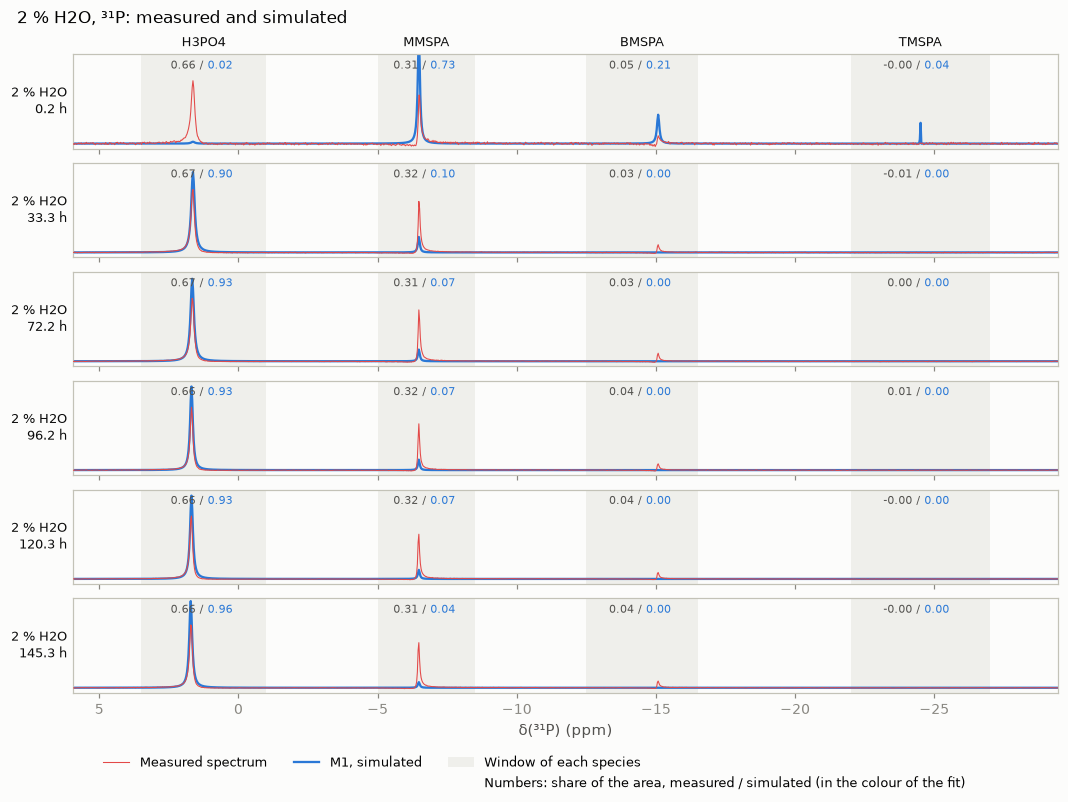

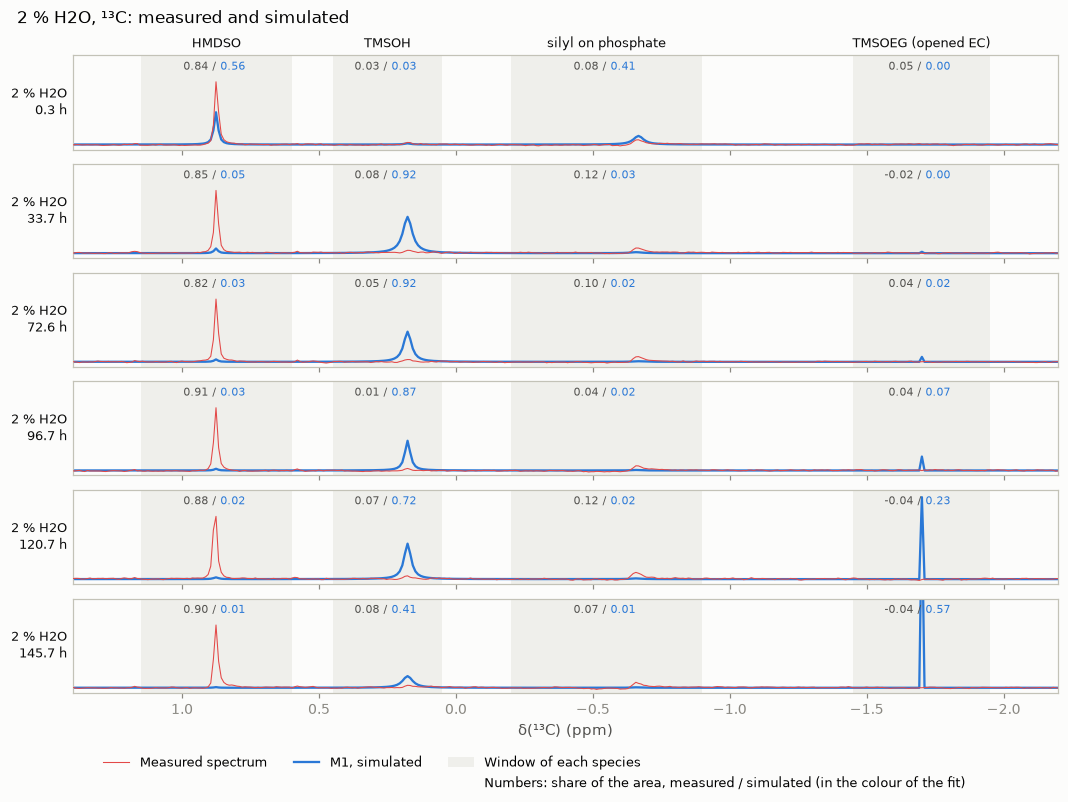

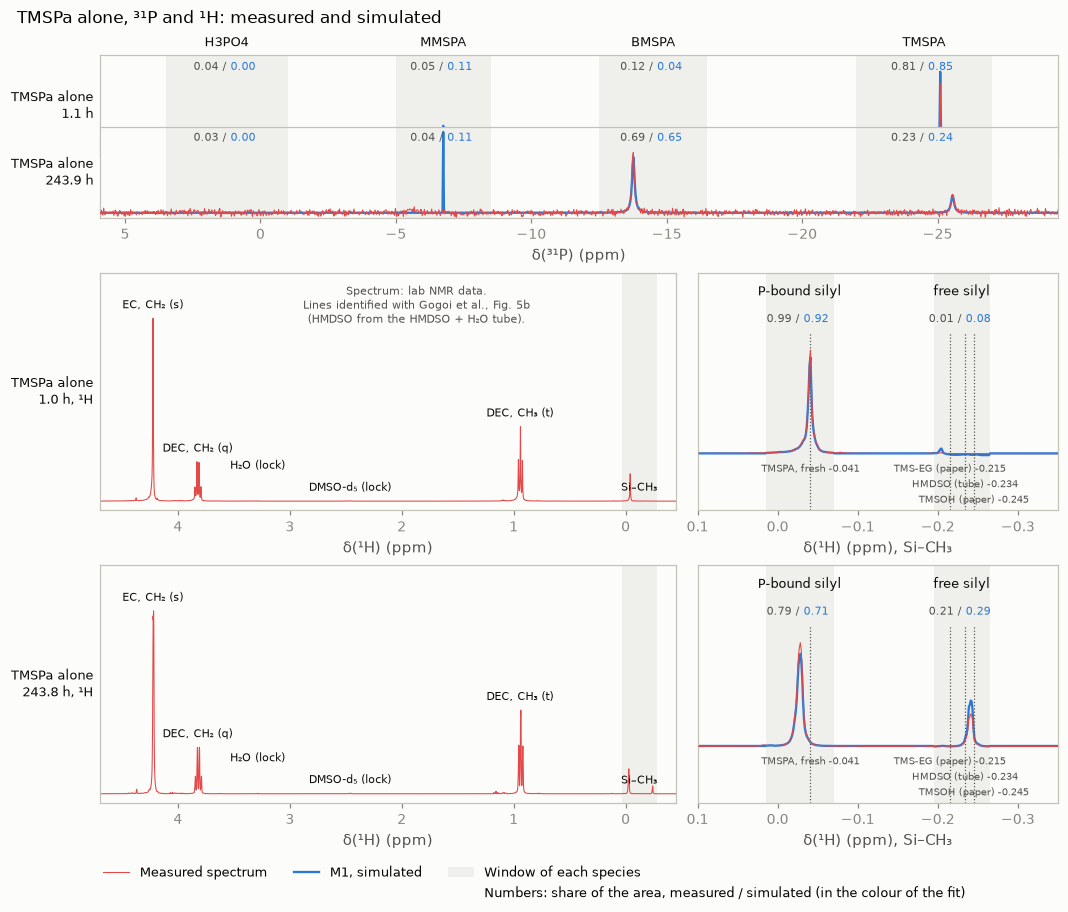

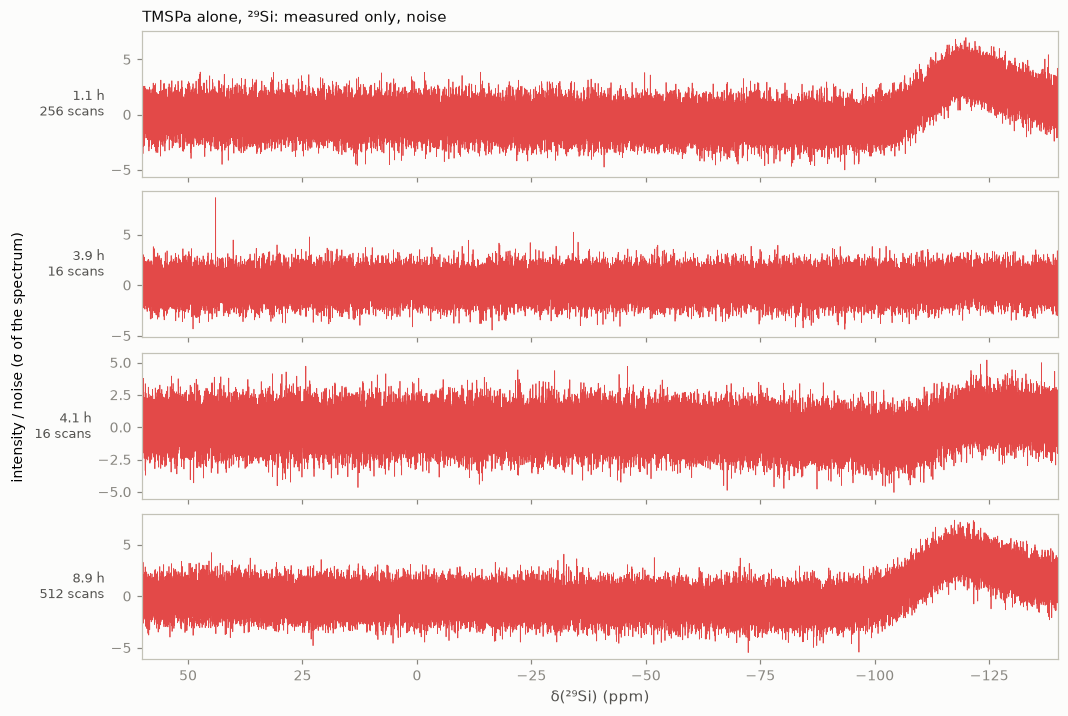

Measured share x the total phosphorus (or silyl groups) of the recipe = a point; error bars are noise and baseline (no floor), the curves are the model.

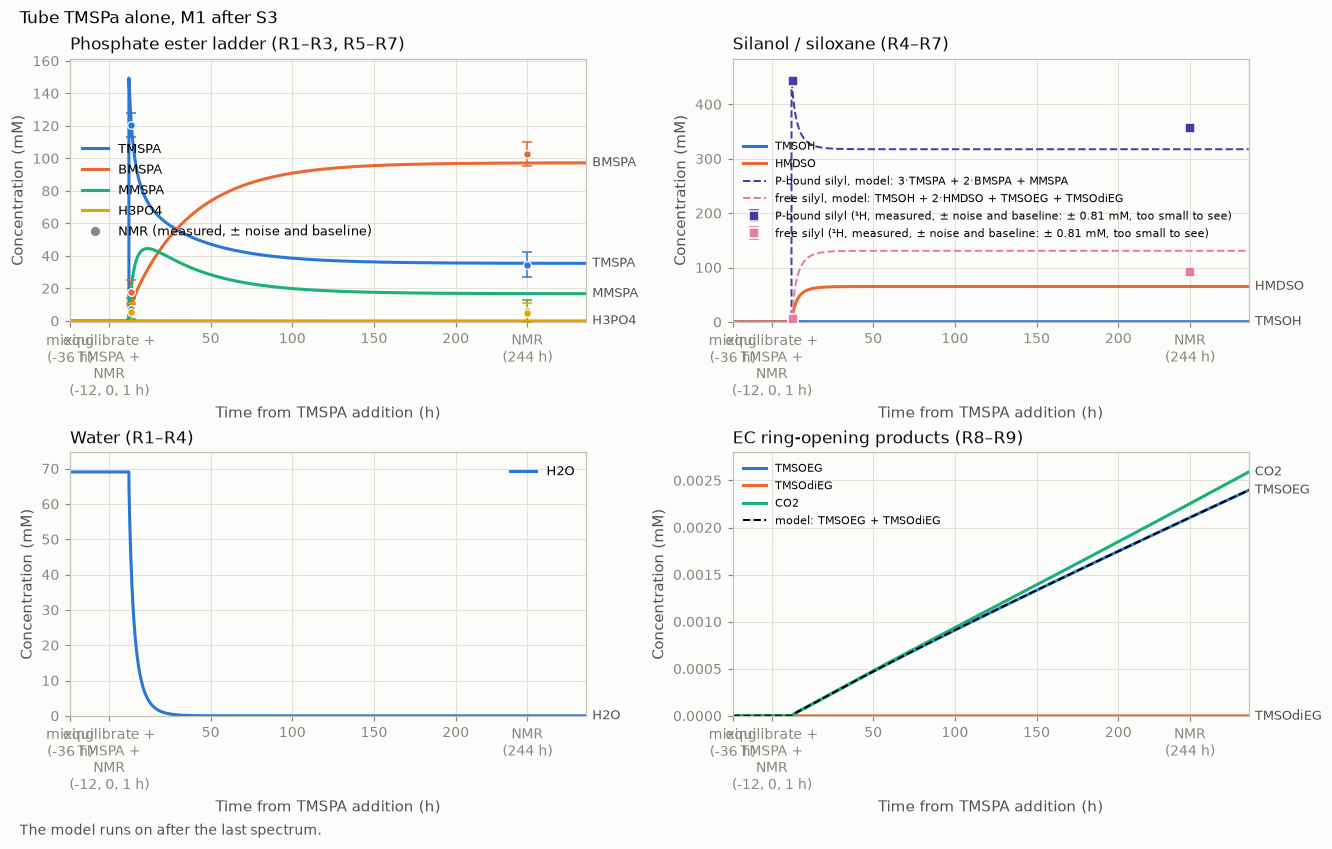